In [1]:
import numpy as np
import torch
import os

from matplotlib import pyplot as plt
import seaborn as sns
from scipy import stats

%load_ext autoreload
%autoreload 2

from utils import generate_run_ID
from place_cells import PlaceCells
from direction_cells import DirectionCells
from trajectory_generator_ini0 import TrajectoryGenerator
from models import LMN_PaS_Conj_mEC
from trainer import Trainer

In [2]:
# Training options and hyperparameters
class Options:
    pass
options = Options()

options.save_dir = './models_4layer/' 
options.n_steps = 1000    # number of training steps
options.epochs = 101       # number of training epochs
options.batch_size = 500      # number of trajectories per batch
options.sequence_length = 20  # number of steps in trajectory
options.learning_rate = 1e-4  # gradient descent learning rate
#early stopping 
options.freeze_pas_patience = 100
options.freeze_pas_min_delta = 1e-8 #0.0001


options.Nd = 128           # number of direction cells
options.Np = 512           # number of place cells
options.Nlmn = 256        # number of LMN cells
options.Npas = 256        # number of PaS cells
options.Ncg = 512         # number of conjuntive mEC cells
options.Ng = 512         # number of mEC cells

options.place_cell_rf = 0.12  # width of place cell center tuning curve (m)
options.surround_scale = 2    # if DoG, ratio of sigma2^2 to sigma1^2
options.direction_cell_rf = 30*np.pi/180  # width of direction cell tuning curve (radians)
options.activation = 'relu'   # recurrent nonlinearity
options.weight_decay_lmn = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_pas = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_conj = 0 # strength of weight decay on recurrent weights in conj RNN
options.weight_decay_mec = 0  # strength of weight decay on recurrent weights in mEC RNN
options.use_pas_layernorm = False  # apply LayerNorm to PaS before feeding Conj
options.DoG = True            # use difference of gaussians tuning curves
options.periodic = False
options.box_width = 2.2       # width of training environment
options.box_height = 2.2      # height of training environment

options.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

options.run_ID = generate_run_ID(options)

place_cells = PlaceCells(options)
direction_cells = DirectionCells(options)
    
model = LMN_PaS_Conj_mEC(options, direction_cells, place_cells).to(options.device)

trajectory_generator = TrajectoryGenerator(options, direction_cells=direction_cells, place_cells=place_cells)

ckpt_path = os.path.join(options.save_dir, options.run_ID, 'most_recent_model.pth')

if os.path.exists(ckpt_path):
    trainer = Trainer(options, model, trajectory_generator, restore=True)
    print(f'Checkpoint exists, skip training: {ckpt_path}')
else:
    trainer = Trainer(options, model, trajectory_generator, restore=False)
    trainer.train(n_epochs=options.epochs, n_steps=options.n_steps, save=True)



Restored trained model from ./models_4layer/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_101_batch_500_length_20_lr_00001/most_recent_model.pth
Checkpoint exists, skip training: ./models_4layer/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_101_batch_500_length_20_lr_00001/most_recent_model.pth


# 1. Knock Out Input From PaS to Conj

## 1.1 Knock Out Input From PaS to Conj: Cumulative mEC error vs Knockout Fraction

In [3]:
# PaS -> Conj random knockout
# plot cumulative mEC decoding error across time for each knockout fraction

import os
import numpy as np
import matplotlib.pyplot as plt
import torch
from tqdm import tqdm
from matplotlib import cm
from matplotlib.colors import Normalize

# ------------------------------------------------------------
# settings
# ------------------------------------------------------------
options.sequence_length = 100
options.batch_size = 100


fractions = np.arange(0.0, .8001, 0.1)   # 0%, 10%, ..., 100%
n_repeats = 20
n_eval_batches = 30
knockout_seed = 12

traj_seed=456

trajectory_generator = TrajectoryGenerator(
    options,
    direction_cells=direction_cells,
    place_cells=place_cells,
    seed=traj_seed,
)


# ------------------------------------------------------------
# helper: get cumulative mEC positional decoding error vs time
# returns shape [T]
# ------------------------------------------------------------
@torch.no_grad()
def compute_cumulative_mec_error_curve(model, trajectory_generator, n_batches=30, device=None):
    """
    For each batch:
      1) run model forward
      2) decode predicted position from mEC logits at each time step
      3) compute Euclidean position error at each time step
      4) cumulative sum over time
    Then average cumulative curves across batches.

    Returns
    -------
    mean_cum_err : np.ndarray, shape [T]
        Mean cumulative positional error over time.
    """
    model.eval()
    cum_err_curves = []

    for _ in range(n_batches):
        batch = trajectory_generator.get_test_batch()
        inputs, outputs, targets = batch

        if device is not None:
            inputs = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in inputs)
            outputs = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in outputs)
            targets = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in targets)

        s, init_actp, ang_v, init_dir_actv = inputs
        pos, mdir = targets

        # forward
        lmn = model.Lmn((ang_v, init_dir_actv))
        pas = model.PaS(lmn, init_dir_actv)

        conj = model.Conj((s, init_actp), pas)
        mec_h = model.mEC((s, init_actp), conj)
        pos_preds = model.mECDecoder(mec_h)   # [T, B, Np]

        # decode predicted position at each time step
        pred_pos = model.place_cells.get_nearest_cell_pos(pos_preds)  # [T, B, 2] expected
        pred_pos = pred_pos.to(pos.device)

        # per-time-step Euclidean error
        step_err = torch.sqrt(((pos - pred_pos) ** 2).sum(-1))   # [T, B]

        # mean over batch, then cumulative over time
        step_err_mean = step_err.mean(dim=1)                     # [T]
        cum_err = torch.cumsum(step_err_mean, dim=0)            # [T]

        cum_err_curves.append(cum_err.detach().cpu().numpy())

    cum_err_curves = np.asarray(cum_err_curves)                 # [n_batches, T]
    mean_cum_err = np.mean(cum_err_curves, axis=0)

    return mean_cum_err


# ------------------------------------------------------------
# helper: run knockout study and collect cumulative-error curves
# ------------------------------------------------------------
def run_random_pas_to_conj_knockout_cumerr(
    model,
    trajectory_generator,
    fractions,
    n_repeats=10,
    n_eval_batches=30,
    rng=None,
):
    """
    Randomly zero PaS input channels into Conj RNN.

    conjRNN takes input [speed, pas_1, ..., pas_Npas], so:
        col 0 = speed
        cols 1:(1+Npas) = PaS units
    """
    if rng is None:
        rng = np.random.default_rng(0)

    T = options.sequence_length

    # input-to-hidden weights of Conj RNN: shape [Ncg, 1 + Npas]
    orig_w_ih = model.conjRNN.weight_ih_l0.detach().clone()

    all_curves = np.full((len(fractions), n_repeats, T), np.nan, dtype=float)

    try:
        for i, frac in enumerate(tqdm(fractions, desc="Knockout fractions")):
            n_ko = int(round(frac * options.Npas))

            for r in range(n_repeats):
                trajectory_generator.set_seed(traj_seed)

                with torch.no_grad():
                    model.conjRNN.weight_ih_l0.copy_(orig_w_ih)

                    if n_ko > 0:
                        ko_idx = rng.choice(options.Npas, size=n_ko, replace=False)
                        model.conjRNN.weight_ih_l0[:, 1 + ko_idx] = 0.0

                curve = compute_cumulative_mec_error_curve(
                    model=model,
                    trajectory_generator=trajectory_generator,
                    n_batches=n_eval_batches,
                )
                all_curves[i, r, :] = curve

    finally:
        with torch.no_grad():
            model.conjRNN.weight_ih_l0.copy_(orig_w_ih)

    mean_curve = np.nanmean(all_curves, axis=1)

    n_valid = np.sum(~np.isnan(all_curves[:, :, 0]), axis=1)
    sem_curve = np.full_like(mean_curve, np.nan, dtype=float)

    for i in range(len(fractions)):
        if n_valid[i] > 1:
            sem_curve[i, :] = (
                np.nanstd(all_curves[i, :, :], axis=0, ddof=1) / np.sqrt(n_valid[i])
            )

    return mean_curve, sem_curve, all_curves

# ------------------------------------------------------------
# run study
# ------------------------------------------------------------
mean_curve, sem_curve, all_curves = run_random_pas_to_conj_knockout_cumerr(
    model=model,
    trajectory_generator=trajectory_generator,
    fractions=fractions,
    n_repeats=n_repeats,
    n_eval_batches=n_eval_batches,
    rng=np.random.default_rng(knockout_seed),
)



Knockout fractions: 100%|██████████| 9/9 [01:01<00:00,  6.83s/it]


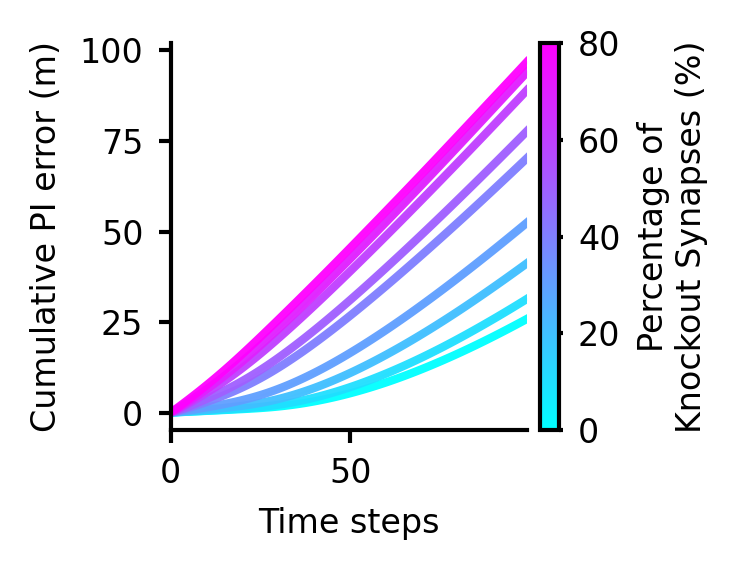

In [4]:
# ------------------------------------------------------------

# plot 1: one panel with all knockout fractions

# ------------------------------------------------------------

time_points = np.arange(options.sequence_length)
x_percent = fractions * 100
n_shutdown_each_frac = np.round(fractions * options.Npas).astype(int)

fig, ax = plt.subplots(figsize=(2.5, 2), dpi=300)

norm = Normalize(vmin=0, vmax=80)
cmap = cm.cool  # 更接近你图里的青->紫风格

for i, (xp, nk) in enumerate(zip(x_percent, n_shutdown_each_frac)):
    color = cmap(norm(xp))

    ax.plot(
        time_points,
        mean_curve[i],
        linewidth=2.0,
        color=color,
        alpha=0.95,
    )

    if sem_curve is not None:
        lower = mean_curve[i] - sem_curve[i]
        upper = mean_curve[i] + sem_curve[i]
        ax.fill_between(
            time_points,
            lower,
            upper,
            color=color,
            alpha=0.20,
            linewidth=0,
        )

ax.set_xlabel("Time steps", fontsize=8)
ax.set_ylabel("Cumulative PI error (m)", fontsize=8)
ax.set_title("", fontsize=12)

ax.set_xlim(0, options.sequence_length - 1)

# 如果你想固定到示例图那种 0-100，可打开下面这句
# ax.set_ylim(0, 100)

# 只保留左、下坐标轴
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.0)
ax.spines["bottom"].set_linewidth(1.0)

ax.tick_params(axis="both", which="major", labelsize=8, width=1.0, length=3)
ax.grid(False)

sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.03)
cbar.set_label("Percentage of\nKnockout Synapses (%)", fontsize=8)
cbar.ax.tick_params(labelsize=8, width=1.0, length=1)
cbar.outline.set_linewidth(1.0)

plt.tight_layout()

plt.savefig(
    "./docs/Knockout_Pas_mEC_CumulativeError.pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


## 1.2 Knock Out Input From PaS to Conj: mEC Grid Score - Knockout Fraction

/home/zilong/Desktop/HRNN4PI/scores.py:137: RuntimeWarning: invalid value encountered in divide
  x_coef = np.divide(covar, np.multiply(std_seq1, std_seq2))


Randomly selected 3 original mEC cells from non-silent cells with grid score > 0.70:
Pick 1: cell 301, grid score = 0.956788
Pick 2: cell 236, grid score = 0.836793
Pick 3: cell 349, grid score = 0.727295
Spatial map shape from activations_mec_0: (512, 20, 20)


Knockout fractions: 100%|██████████| 5/5 [00:10<00:00,  2.09s/it]


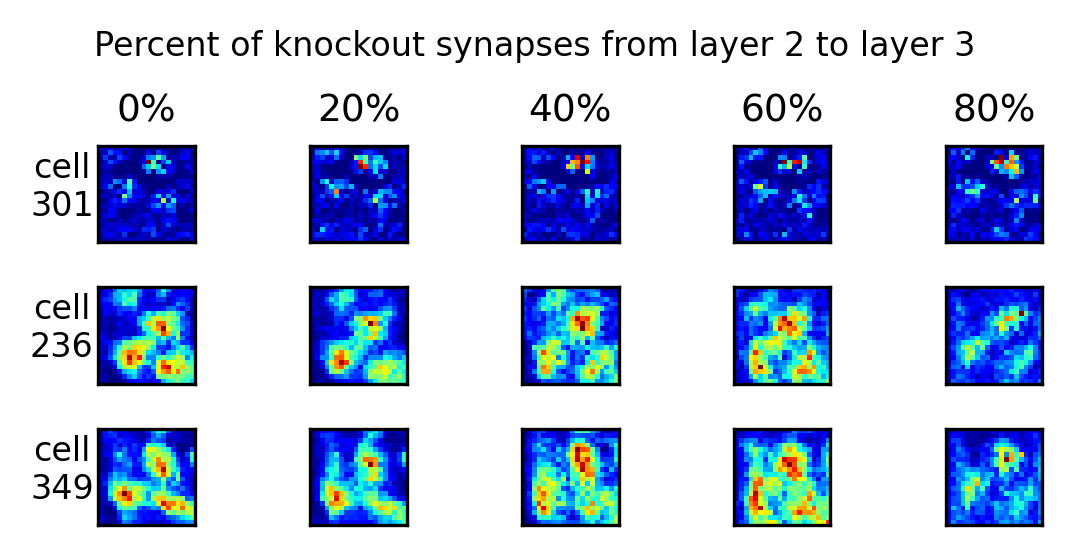

In [5]:
import math
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm

from trajectory_generator_ini0 import TrajectoryGenerator
from visualize import compute_ratemaps_lmn_pas_conj_mec
from scores import GridScorer

# ============================================================
# settings
# ============================================================
options.sequence_length = 100
options.batch_size = 100

traj_seed = 456
res = 60
n_avg = 10
thr = 1e-8

n_cell = 3
selection_seed = 0
grid_score_threshold = 0.7

fractions = np.arange(0, 0.8001, 0.2)
n_repeats = 1
knockout_seed = 123

# ============================================================
# trajectory generator
# ============================================================
trajectory_generator = TrajectoryGenerator(
    options,
    direction_cells=direction_cells,
    place_cells=place_cells,
    seed=traj_seed,
    init_point="random",
)

# ============================================================
# helper
# ============================================================
def reset_traj_seed(traj_gen, seed_value):
    if hasattr(traj_gen, "set_seed"):
        traj_gen.set_seed(seed_value)
    elif hasattr(traj_gen, "seed"):
        traj_gen.seed = seed_value
    elif hasattr(traj_gen, "rng"):
        traj_gen.rng = np.random.default_rng(seed_value)

# ============================================================
# helper 1: compute ORIGINAL grid scores only once
# ============================================================
def compute_original_grid_scores_and_maps(
    model,
    trajectory_generator,
    options,
    res=60,
    n_avg=20,
    thr=1e-8,
):
    results = compute_ratemaps_lmn_pas_conj_mec(
        model,
        trajectory_generator,
        options,
        res=res,
        n_avg=n_avg,
        N_lmn=options.Nlmn,
        N_pas=options.Npas,
        N_conj=options.Ncg,
        N_mec=options.Ng,
    )

    (
        activations_lmn_dir,
        rate_map_lmn_dir,
        activations_pas_dir,
        rate_map_pas_dir,
        activations_conj_dir,
        rate_map_conj_dir,
        activations_mec_dir,
        rate_map_mec_dir,
        activations_lmn_spatial,
        rate_map_lmn_spatial,
        activations_pas_spatial,
        rate_map_pas_spatial,
        activations_conj_spatial,
        rate_map_conj_spatial,
        activations_mec_spatial,
        rate_map_mec_spatial,
        lmn,
        pas,
        conj,
        mec,
        ang,
        pos,
    ) = results

    keep_spatial_mec = np.max(np.abs(activations_mec_spatial), axis=(1, 2)) > thr
    keep_trace_mec = np.max(np.abs(mec), axis=0) > thr
    keep_mec = keep_spatial_mec & keep_trace_mec

    rm_mec_ns = activations_mec_spatial[keep_mec]

    res_pos_here = activations_mec_spatial.shape[-1]
    starts = [0.2] * 10
    ends = np.linspace(0.4, 1.0, num=10)

    coord_range = (
        (-options.box_width / 2, options.box_width / 2),
        (-options.box_height / 2, options.box_height / 2),
    )

    scorer = GridScorer(
        res_pos_here,
        coord_range,
        zip(starts, ends.tolist()),
    )

    if rm_mec_ns.shape[0] > 0:
        (
            score_60_mec,
            score_90_mec,
            max_60_mask_mec,
            max_90_mask_mec,
            sac_mec,
            max_60_ind_mec,
        ) = zip(*[
            scorer.get_scores(rm.reshape(res_pos_here, res_pos_here))
            for rm in rm_mec_ns
        ])
        grid_score_mec = np.asarray(score_60_mec)
    else:
        grid_score_mec = np.array([])

    return (
        grid_score_mec,
        keep_mec,
        activations_mec_spatial,
        rate_map_mec_spatial,
        mec,
        ang,
        pos,
    )

# ============================================================
# helper 2: for each fraction, compute maps only
# ============================================================
def compute_current_mec_maps_only(
    model,
    trajectory_generator,
    options,
    res=60,
    n_avg=10,
):
    results = compute_ratemaps_lmn_pas_conj_mec(
        model,
        trajectory_generator,
        options,
        res=res,
        n_avg=n_avg,
        N_lmn=options.Nlmn,
        N_pas=options.Npas,
        N_conj=options.Ncg,
        N_mec=options.Ng,
    )

    (
        activations_lmn_dir,
        rate_map_lmn_dir,
        activations_pas_dir,
        rate_map_pas_dir,
        activations_conj_dir,
        rate_map_conj_dir,
        activations_mec_dir,
        rate_map_mec_dir,
        activations_lmn_spatial,
        rate_map_lmn_spatial,
        activations_pas_spatial,
        rate_map_pas_spatial,
        activations_conj_spatial,
        rate_map_conj_spatial,
        activations_mec_spatial,
        rate_map_mec_spatial,
        lmn,
        pas,
        conj,
        mec,
        ang,
        pos,
    ) = results

    return activations_mec_spatial

# ============================================================
# save original PaS -> Conj input weights
# conjRNN input is [speed, pas_1, ..., pas_Npas]
# so col 0 = speed, cols 1: = PaS cells
# ============================================================
orig_w_ih = model.conjRNN.weight_ih_l0.detach().clone()

model.eval()

# ============================================================
# 1) randomly choose n_cell original mEC cells from
#    non-silent cells with grid score > threshold
# ============================================================
reset_traj_seed(trajectory_generator, traj_seed)

with torch.no_grad():
    model.conjRNN.weight_ih_l0.copy_(orig_w_ih)

(
    grid_score_mec_0,
    keep_mec_0,
    activations_mec_0,
    rate_map_mec_0,
    mec_0,
    ang_0,
    pos_0,
) = compute_original_grid_scores_and_maps(
    model,
    trajectory_generator,
    options,
    res=res,
    n_avg=n_avg,
    thr=thr,
)

mec_keep_ids_0 = np.where(keep_mec_0)[0]

candidate_mask = grid_score_mec_0 > grid_score_threshold
candidate_ids = mec_keep_ids_0[candidate_mask]
candidate_scores = grid_score_mec_0[candidate_mask]

if candidate_ids.size < n_cell:
    raise ValueError(
        f"Only {candidate_ids.size} non-silent mEC cells with grid score > "
        f"{grid_score_threshold:.2f}; cannot sample {n_cell} cells."
    )

selection_rng = np.random.default_rng(selection_seed)
chosen_idx = selection_rng.choice(candidate_ids.size, size=n_cell, replace=False)

top_mec_ids = candidate_ids[chosen_idx]
top_mec_scores = candidate_scores[chosen_idx]

# optional: sort selected cells by grid score descending for a more stable display order
order = np.argsort(top_mec_scores)[::-1]
top_mec_ids = top_mec_ids[order]
top_mec_scores = top_mec_scores[order]

print(
    f"Randomly selected {n_cell} original mEC cells "
    f"from non-silent cells with grid score > {grid_score_threshold:.2f}:"
)
for rank, (cid, gs) in enumerate(zip(top_mec_ids, top_mec_scores), start=1):
    print(f"Pick {rank}: cell {cid}, grid score = {gs:.6f}")

print("Spatial map shape from activations_mec_0:", activations_mec_0.shape)

# ============================================================
# 2) for each fraction, average across repeats
#    for the SAME selected original mEC cells
# ============================================================
rng = np.random.default_rng(knockout_seed)
n_frac = len(fractions)

top_maps_mean = None

try:
    for i, frac in enumerate(tqdm(fractions, desc="Knockout fractions")):
        n_ko = int(round(frac * options.Npas))

        frac_maps = [[] for _ in range(n_cell)]

        for r in range(n_repeats):
            reset_traj_seed(trajectory_generator, traj_seed)

            with torch.no_grad():
                model.conjRNN.weight_ih_l0.copy_(orig_w_ih)

                if n_ko > 0:
                    ko_idx = rng.choice(options.Npas, size=n_ko, replace=False)
                    model.conjRNN.weight_ih_l0[:, 1 + ko_idx] = 0.0
                else:
                    ko_idx = np.array([], dtype=int)

            if frac == 0:
                activations_mec = activations_mec_0.copy()
            else:
                activations_mec = compute_current_mec_maps_only(
                    model,
                    trajectory_generator,
                    options,
                    res=res,
                    n_avg=n_avg,
                )

            if top_maps_mean is None:
                map_h, map_w = activations_mec.shape[1], activations_mec.shape[2]
                top_maps_mean = np.zeros(
                    (n_cell, n_frac, map_h, map_w),
                    dtype=np.float64,
                )

            for j, cell_id in enumerate(top_mec_ids):
                frac_maps[j].append(
                    np.asarray(activations_mec[cell_id], dtype=np.float64)
                )

        for j in range(n_cell):
            frac_stack = np.stack(frac_maps[j], axis=0)
            top_maps_mean[j, i] = np.mean(frac_stack, axis=0)

finally:
    with torch.no_grad():
        model.conjRNN.weight_ih_l0.copy_(orig_w_ih)

# ============================================================
# 3) plot n_cell x n_frac
# ============================================================
n_rows = n_cell
n_cols = n_frac

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4, 2),
    dpi=300,
)

if n_rows == 1:
    axes = axes[None, :]
if n_cols == 1:
    axes = axes[:, None]

for row in range(n_cell):
    for col, frac in enumerate(fractions):
        ax = axes[row, col]

        this_map = top_maps_mean[row, col]
        vmin = np.min(this_map)
        vmax = np.max(this_map)

        if np.isclose(vmin, vmax):
            vmax = vmin + 1e-12

        ax.imshow(
            this_map,
            cmap="jet",
            origin="lower",
            vmin=vmin,
            vmax=vmax,
        )

        ax.set_xticks([])
        ax.set_yticks([])

        if row == 0:
            ax.set_title(f"{int(round(frac * 100))}%", fontsize=9)

        if col == 0:
            ax.set_ylabel(
                f"cell\n{top_mec_ids[row]}",
                fontsize=8,
                rotation=0,
                labelpad=20,
            )
            ax.yaxis.set_label_coords(-0.38, 0.2)

plt.suptitle(
    "Percent of knockout synapses from layer 2 to layer 3",
    fontsize=8,
    y=0.9,
)
plt.tight_layout()

plt.savefig(
    "./docs/Knockout_Pas_Conj_GridScore_Examples.pdf",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 1.3 Knock Out Input From PaS to Conj: mEC Grid Score stats

In [6]:
# Knock Out Input From PaS to Conj: mEC Grid Score (4-layer model)
import os
import numpy as np
import matplotlib.pyplot as plt
import torch

from tqdm import tqdm
from trajectory_generator_ini0 import TrajectoryGenerator
from visualize import compute_ratemaps_lmn_pas_conj_mec
from scores import GridScorer

# ============================================================
# Plot for Each Fraction
# PaS -> Conj perturbation study in LMN-PaS-Conj-mEC model:
# knock out different fractions of PaS outputs to Conj
# x = knockout fraction (%)
# y = mean grid score of non-silent mEC cells
# additionally: save per-iteration data only
# ============================================================

# ------------------------------------------------------------
# settings
# ------------------------------------------------------------
options.sequence_length = 100
options.batch_size = 100

n_avg = 10
n_repeats = 20

traj_seed = 456
knockout_seed = 123

fractions = np.arange(0, 0.8001, 0.1)   # 0%, 5%, ..., 80%

trajectory_generator = TrajectoryGenerator(
    options,
    direction_cells=direction_cells,
    place_cells=place_cells,
    seed=traj_seed,
    init_point="same",
)

res = 60
thr = 1e-8

# where to save plots / data
save_root = "./simulated_data"
os.makedirs(save_root, exist_ok=True)

summary_fig_path = os.path.join(
    save_root,
    "summary_grid_score_vs_pas_to_conj_knockout_4layer.png"
)

summary_data_path = os.path.join(
    save_root,
    "summary_grid_score_vs_pas_to_conj_knockout_4layer_data.npz"
)

# ------------------------------------------------------------
# helper
# ------------------------------------------------------------
def reset_traj_seed(traj_gen, seed_value):
    if hasattr(traj_gen, "set_seed"):
        traj_gen.set_seed(seed_value)
    elif hasattr(traj_gen, "seed"):
        traj_gen.seed = seed_value
    elif hasattr(traj_gen, "rng"):
        traj_gen.rng = np.random.default_rng(seed_value)


# ------------------------------------------------------------
# helper: compute grid scores for CURRENT model weights
# and also return mEC activations and keep mask
# ------------------------------------------------------------
def compute_grid_scores_current_model(
    model,
    trajectory_generator,
    options,
    res=60,
    n_avg=10,
    thr=1e-8,
):
    results = compute_ratemaps_lmn_pas_conj_mec(
        model,
        trajectory_generator,
        options,
        res=res,
        n_avg=n_avg,
        N_lmn=options.Nlmn,
        N_pas=options.Npas,
        N_conj=options.Ncg,
        N_mec=options.Ng,
    )

    (
        activations_lmn_dir,
        rate_map_lmn_dir,
        activations_pas_dir,
        rate_map_pas_dir,
        activations_conj_dir,
        rate_map_conj_dir,
        activations_mec_dir,
        rate_map_mec_dir,
        activations_lmn_spatial,
        rate_map_lmn_spatial,
        activations_pas_spatial,
        rate_map_pas_spatial,
        activations_conj_spatial,
        rate_map_conj_spatial,
        activations_mec_spatial,
        rate_map_mec_spatial,
        lmn,
        pas,
        conj,
        mec,
        ang,
        pos,
    ) = results

    # keep non-silent mEC cells
    keep_spatial_mec = np.max(np.abs(activations_mec_spatial), axis=(1, 2)) > thr
    keep_trace_mec = np.max(np.abs(mec), axis=0) > thr
    keep_mec = keep_spatial_mec & keep_trace_mec

    # use activations_mec_spatial for grid score
    rm_mec_ns = activations_mec_spatial[keep_mec]

    res_pos_here = activations_mec_spatial.shape[-1]

    starts = [0.2] * 10
    ends = np.linspace(0.4, 1.0, num=10)

    coord_range = (
        (-options.box_width / 2, options.box_width / 2),
        (-options.box_height / 2, options.box_height / 2),
    )

    scorer = GridScorer(
        res_pos_here,
        coord_range,
        zip(starts, ends.tolist())
    )

    if rm_mec_ns.shape[0] > 0:
        (
            score_60_mec,
            score_90_mec,
            max_60_mask_mec,
            max_90_mask_mec,
            sac_mec,
            max_60_ind_mec,
        ) = zip(*[
            scorer.get_scores(rm.reshape(res_pos_here, res_pos_here))
            for rm in rm_mec_ns
        ])
        grid_score_mec = np.asarray(score_60_mec)
    else:
        grid_score_mec = np.array([])

    return (
        grid_score_mec,
        keep_mec,
        activations_mec_spatial,
        mec,
        ang,
        pos,
    )

# ------------------------------------------------------------
# save original PaS -> Conj input weights
# conjRNN input is [speed, pas_1, ..., pas_Npas]
# so column 0 = speed, columns 1: = PaS cells
# ------------------------------------------------------------
orig_w_ih = model.conjRNN.weight_ih_l0.detach().clone()

model.eval()

if os.path.exists(summary_data_path):
    print("Summary data already exists, skip running knockout evaluation:")
    print(summary_data_path)

    summary_data = np.load(summary_data_path, allow_pickle=True)

    fractions = summary_data["fractions"]
    x_percent = summary_data["x_percent"]
    all_mean_scores_mec = summary_data["all_mean_scores_mec"]
    all_median_scores_mec = summary_data["all_median_scores_mec"]
    all_n_kept_mec = summary_data["all_n_kept_mec"]
    mean_curve_mec = summary_data["mean_curve_mec"]
    sem_curve_mec = summary_data["sem_curve_mec"]
    median_curve_mec = summary_data["median_curve_mec"]
    mean_n_kept_mec = summary_data["mean_n_kept_mec"]
    valid_counts_mec = summary_data["valid_counts_mec"]

else:
    all_mean_scores_mec = np.full((len(fractions), n_repeats), np.nan)
    all_median_scores_mec = np.full((len(fractions), n_repeats), np.nan)
    all_n_kept_mec = np.zeros((len(fractions), n_repeats), dtype=int)

    try:
        for i, frac in enumerate(tqdm(fractions, desc="Knockout fractions")):
            n_ko = int(round(frac * options.Npas))
            frac_percent = int(round(frac * 100))

            frac_dir = save_root
            os.makedirs(frac_dir, exist_ok=True)

            for r in range(n_repeats):
                traj_seed_this = traj_seed
                reset_traj_seed(trajectory_generator, traj_seed)

                with torch.no_grad():
                    model.conjRNN.weight_ih_l0.copy_(orig_w_ih)

                    if n_ko > 0:
                        rng_this = np.random.default_rng(
                            knockout_seed + 10000 * i + r
                        )

                        ko_idx = rng_this.choice(
                            options.Npas,
                            size=n_ko,
                            replace=False
                        )

                        model.conjRNN.weight_ih_l0[:, 1 + ko_idx] = 0.0
                    else:
                        ko_idx = np.array([], dtype=int)

                (
                    grid_score_mec,
                    keep_mec,
                    activations_mec,
                    mec,
                    ang,
                    pos,
                ) = compute_grid_scores_current_model(
                    model,
                    trajectory_generator,
                    options,
                    res=res,
                    n_avg=n_avg,
                    thr=thr,
                )

                all_n_kept_mec[i, r] = int(np.sum(keep_mec))

                if grid_score_mec.size > 0:
                    all_mean_scores_mec[i, r] = np.nanmean(grid_score_mec)
                    all_median_scores_mec[i, r] = np.nanmedian(grid_score_mec)

                iter_data_path = os.path.join(
                    frac_dir,
                    f"iter_data_frac_{frac_percent:03d}_repeat_{r+1:02d}.npz"
                )

                np.savez(
                    iter_data_path,
                    frac=frac,
                    frac_percent=frac_percent,
                    repeat_index=r,
                    repeat_number=r + 1,
                    n_ko=n_ko,
                    ko_idx=ko_idx,
                    traj_seed_this=traj_seed_this,
                    knockout_seed_this=knockout_seed + 10000 * i + r,
                    grid_score_mec=grid_score_mec,
                    keep_mec=keep_mec,
                )

    finally:
        with torch.no_grad():
            model.conjRNN.weight_ih_l0.copy_(orig_w_ih)

    x_percent = fractions * 100.0

    mean_curve_mec = np.nanmean(all_mean_scores_mec, axis=1)
    valid_counts_mec = np.sum(~np.isnan(all_mean_scores_mec), axis=1)

    sem_curve_mec = np.full_like(mean_curve_mec, np.nan, dtype=float)
    ok_mec = valid_counts_mec > 1

    sem_curve_mec[ok_mec] = (
        np.nanstd(all_mean_scores_mec[ok_mec], axis=1, ddof=1)
        / np.sqrt(valid_counts_mec[ok_mec])
    )

    median_curve_mec = np.nanmean(all_median_scores_mec, axis=1)
    mean_n_kept_mec = np.mean(all_n_kept_mec, axis=1)

    np.savez(
        summary_data_path,
        fractions=fractions,
        x_percent=x_percent,
        all_mean_scores_mec=all_mean_scores_mec,
        all_median_scores_mec=all_median_scores_mec,
        all_n_kept_mec=all_n_kept_mec,
        mean_curve_mec=mean_curve_mec,
        sem_curve_mec=sem_curve_mec,
        median_curve_mec=median_curve_mec,
        mean_n_kept_mec=mean_n_kept_mec,
        valid_counts_mec=valid_counts_mec,
        traj_seed=traj_seed,
        knockout_seed=knockout_seed,
        n_repeats=n_repeats,
        res=res,
        n_avg=n_avg,
    )

    print("Saved summary data to:", summary_data_path)


Summary data already exists, skip running knockout evaluation:
./simulated_data/summary_grid_score_vs_pas_to_conj_knockout_4layer_data.npz


Summary figure already exists, plotting without overwriting:
./simulated_data/summary_grid_score_vs_pas_to_conj_knockout_4layer.png


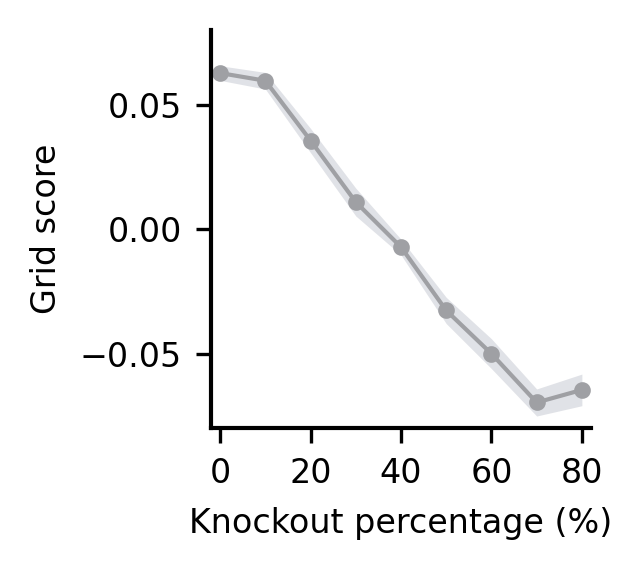

In [7]:
# ------------------------------------------------------------
# plot summary curve
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(2.2, 2), dpi=300)

line_color = "#9fa0a4"
fill_color = "#d9dbe1"

ax.plot(
    x_percent,
    mean_curve_mec,
    color=line_color,
    linewidth=1,
    marker="o",
    markersize=3,
    markerfacecolor=line_color,
    markeredgecolor=line_color,
)

ax.fill_between(
    x_percent,
    mean_curve_mec - sem_curve_mec,
    mean_curve_mec + sem_curve_mec,
    color=fill_color,
    alpha=0.8,
    linewidth=0,
)

ax.set_xlabel("Knockout percentage (%)", fontsize=8)
ax.set_ylabel("Grid score", fontsize=8)

ax.set_xticks([0, 20, 40, 60, 80])
ax.set_yticks([-0.05, 0.00, 0.05])

# 如果你想把显示范围也卡住，可以加这两句
ax.set_xlim(-2, 82)
ax.set_ylim(-0.08, 0.08)
ax.set_yticks([-0.05, 0.00, 0.05])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.0)
ax.spines["bottom"].set_linewidth(1.0)

ax.tick_params(
    axis="both",
    which="major",
    labelsize=8,
)

ax.grid(False)

plt.tight_layout()

if os.path.exists(summary_fig_path):
    print("Summary figure already exists, plotting without overwriting:")
    print(summary_fig_path)
else:
    plt.savefig(summary_fig_path, dpi=300, bbox_inches="tight")
    print("Saved summary figure to:", summary_fig_path)

plt.savefig("./docs/Knockout_Pas_Conj_GridScore.pdf", dpi=300, bbox_inches="tight")

# 2. Shutdown mEC (grid & non-grid)

In [8]:
#Load Model Again
# Training options and hyperparameters
class Options:
    pass
options = Options()

options.save_dir = './models_4layer/' 
options.n_steps = 1000    # number of training steps
options.epochs = 101       # number of training epochs
options.batch_size = 500      # number of trajectories per batch
options.sequence_length = 20  # number of steps in trajectory
options.learning_rate = 1e-4  # gradient descent learning rate
#early stopping 
options.freeze_pas_patience = 100
options.freeze_pas_min_delta = 1e-9 #0.0001


options.Nd = 128           # number of direction cells
options.Np = 512            # number of place cells
options.Nlmn = 256        # number of LMN cells
options.Npas = 256        # number of PaS cells
options.Ncg = 512         # number of conjuntive mEC cells
options.Ng = 512         # number of mEC cells

options.place_cell_rf = 0.12  # width of place cell center tuning curve (m)
options.surround_scale = 2    # if DoG, ratio of sigma2^2 to sigma1^2
options.direction_cell_rf = 30*np.pi/180  # width of direction cell tuning curve (radians)
options.activation = 'relu'   # recurrent nonlinearity
options.weight_decay_lmn = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_pas = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_conj = 0 # strength of weight decay on recurrent weights in conj RNN
options.weight_decay_mec = 0  # strength of weight decay on recurrent weights in mEC RNN
options.DoG = True            # use difference of gaussians tuning curves
options.periodic = False
options.box_width = 2.2       # width of training environment
options.box_height = 2.2      # height of training environment

options.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

options.run_ID = generate_run_ID(options)

place_cells = PlaceCells(options)
direction_cells = DirectionCells(options)
    
model = LMN_PaS_Conj_mEC(options, direction_cells, place_cells).to(options.device)

trajectory_generator = TrajectoryGenerator(options, direction_cells=direction_cells, place_cells=place_cells)

ckpt_path = os.path.join(options.save_dir, options.run_ID, 'most_recent_model.pth')

if os.path.exists(ckpt_path):
    trainer = Trainer(options, model, trajectory_generator, restore=True)
    print(f'Checkpoint exists, skip training: {ckpt_path}')
else:
    trainer = Trainer(options, model, trajectory_generator, restore=False)
    trainer.train(n_epochs=options.epochs, n_steps=options.n_steps, save=True)




Restored trained model from ./models_4layer/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_101_batch_500_length_20_lr_00001/most_recent_model.pth
Checkpoint exists, skip training: ./models_4layer/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_101_batch_500_length_20_lr_00001/most_recent_model.pth


## 2.1 Shutdown Input From Conj to mEC

non-silent mEC cells: 490/512


mEC grid scores:   0%|          | 0/490 [00:00<?, ?it/s]/home/zilong/Desktop/HRNN4PI/scores.py:137: RuntimeWarning: invalid value encountered in divide
  x_coef = np.divide(covar, np.multiply(std_seq1, std_seq2))
mEC grid scores: 100%|██████████| 490/490 [00:02<00:00, 219.63it/s]


mEC grid cells (score > 0.3):      128
mEC non-grid cells (score < 0.3):  362

Matched comparison cap = min(grid, non-grid) = 128
For each fraction f, both curves shut down round(f * n_cap) mEC cells.


Fractions: 100%|██████████| 11/11 [00:40<00:00,  3.68s/it]


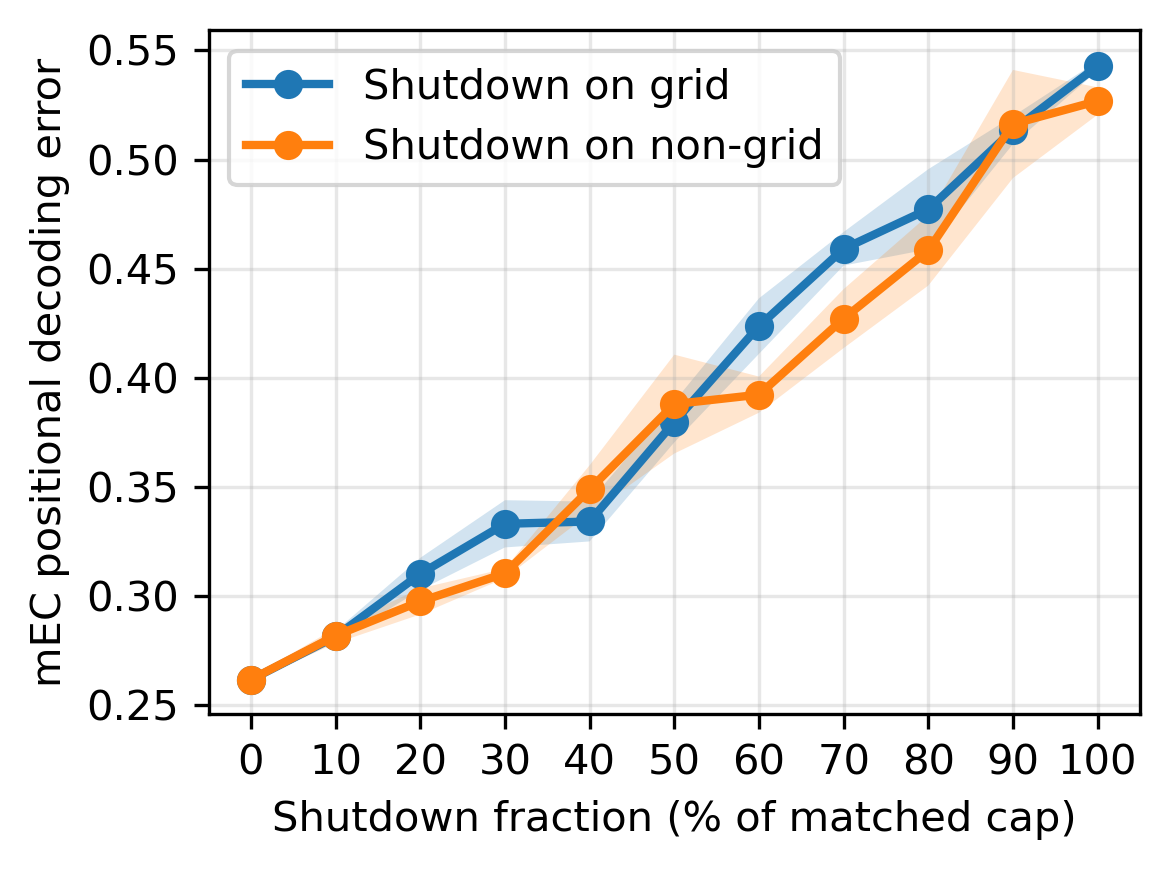

In [9]:
#Shutdown Input From Conj to mEC:
# Shut Down Conj -> mEC Input Weights Onto Grid vs Non-Grid mEC Cells Separately
# ============================================================
# Perturbation study for LMN-PaS-Conj-mEC model:
# identify grid vs non-grid cells in the mEC layer using
# grid score threshold, then shut down Conj->mEC input weights
# onto these mEC target cells separately, and measure
# mEC positional decoding error.
#
# IMPORTANT:
# - compare the two target groups using the SAME absolute number
#   of shut-down mEC cells
# - cap = min(number of grid mEC cells, number of non-grid mEC cells)
#
# x = shutdown fraction (% of cap)
# y = mEC positional decoding error
#
# In torch.nn.RNN:
#   model.mECRNN.weight_ih_l0 has shape [Ng, Ncg]
#   rows = target mEC cells
#   cols = input Conj cells
#
# So zeroing selected ROWS disables all Conj input into those
# selected mEC cells.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch

from visualize import compute_ratemaps_lmn_pas_conj_mec
from scores import GridScorer
from tqdm import tqdm

# ------------------------------------------------------------
# settings
# ------------------------------------------------------------
options.sequence_length = 100
options.batch_size = 100

res = 60
n_avg = 10
thr = 1e-8

grid_thr = 0.3

fractions = np.arange(0.0, 1.0001, 0.10)   # 0%, 10%, ..., 100%
n_repeats = 10
n_eval_batches = 30
seed = 12 #seed for shutdown cell id
traj_seed=123 #seed for trajecotry 

trajectory_generator = TrajectoryGenerator(
    options,
    direction_cells=direction_cells,
    place_cells=place_cells,
    seed=traj_seed,
)



# ------------------------------------------------------------
# helpers
# ------------------------------------------------------------
def compute_original_mec_cell_types(model, trajectory_generator, options, res=60, n_avg=100, thr=1e-8):
    """
    Determine grid vs non-grid cell types from the ORIGINAL
    unperturbed model, using the mEC layer.

    grid:     grid score > grid_thr
    non-grid: grid score < grid_thr
    """
    model.eval()

    results = compute_ratemaps_lmn_pas_conj_mec(
        model,
        trajectory_generator,
        options,
        res=res,
        n_avg=n_avg,
        N_lmn=options.Nlmn,
        N_pas=options.Npas,
        N_conj=options.Ncg,
        N_mec=options.Ng,
    )

    (
        activations_lmn_dir,
        rate_map_lmn_dir,
        activations_pas_dir,
        rate_map_pas_dir,
        activations_conj_dir,
        rate_map_conj_dir,
        activations_mec_dir,
        rate_map_mec_dir,
        activations_lmn_spatial,
        rate_map_lmn_spatial,
        activations_pas_spatial,
        rate_map_pas_spatial,
        activations_conj_spatial,
        rate_map_conj_spatial,
        activations_mec_spatial,
        rate_map_mec_spatial,
        lmn,
        pas,
        conj,
        mec,
        ang,
        pos,
    ) = results

    # keep non-silent mEC cells
    keep_spatial = np.max(np.abs(activations_mec_spatial), axis=(1, 2)) > thr
    keep_trace = np.max(np.abs(mec), axis=0) > thr
    keep = keep_spatial & keep_trace

    orig_ids = np.where(keep)[0]
    rm_mec_ns = rate_map_mec_spatial[keep]   # [N_keep, res*res]
    mec_ns = mec[:, keep]                    # [T, N_keep]

    print(f"non-silent mEC cells: {mec_ns.shape[1]}/{mec.shape[1]}")

    # grid score for mEC cells
    res_pos = activations_mec_spatial.shape[-1]
    starts = [0.2] * 10
    ends = np.linspace(0.4, 1.0, num=10)

    coord_range = (
        (-options.box_width / 2, options.box_width / 2),
        (-options.box_height / 2, options.box_height / 2),
    )

    scorer = GridScorer(res_pos, coord_range, zip(starts, ends.tolist()))

    score_60, score_90, max_60_mask, max_90_mask, sac, max_60_ind = zip(
        *[scorer.get_scores(rm.reshape(res_pos, res_pos)) for rm in tqdm(rm_mec_ns, desc="mEC grid scores")]
    )
    grid_score_ns = np.asarray(score_60)

    # classify among non-silent mEC cells
    grid_mask_ns = grid_score_ns > grid_thr
    nongrid_mask_ns = grid_score_ns < grid_thr

    grid_ids = orig_ids[grid_mask_ns]
    nongrid_ids = orig_ids[nongrid_mask_ns]

    print(f"mEC grid cells (score > {grid_thr}):      {len(grid_ids)}")
    print(f"mEC non-grid cells (score < {grid_thr}):  {len(nongrid_ids)}")

    return {
        "keep": keep,
        "orig_ids": orig_ids,
        "grid_score_ns": grid_score_ns,
        "grid_ids": grid_ids,
        "nongrid_ids": nongrid_ids,
    }


@torch.no_grad()
def compute_mean_position_error(model, trajectory_generator, n_batches=30, device=None):
    errs = []

    model.eval()

    for _ in range(n_batches):
        batch = trajectory_generator.get_test_batch()
        inputs, outputs, targets = batch

        if device is not None:
            inputs = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in inputs)
            outputs = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in outputs)
            targets = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in targets)

        loss, loss_pas, loss_mec, err_pas, err_mec = model.compute_loss(inputs, outputs, targets)
        errs.append(float(err_mec.detach().cpu().item()))

    return np.mean(errs)


def run_targeted_shutdown_curve_capped(model, trajectory_generator, target_ids, n_cap, fractions,
                                       n_repeats=10, n_eval_batches=30, rng=None):
    """
    For each fraction, shut down the SAME ABSOLUTE NUMBER of mEC target cells:
        n_ko = round(frac * n_cap)

    target_ids can be grid_ids or nongrid_ids, but both curves use the same n_cap.

    Shutdown means:
        - select n_ko mEC units from target_ids
        - zero all Conj->mEC input weights onto those selected mEC cells
          by setting the corresponding rows of mECRNN.weight_ih_l0 to zero

    In torch.nn.RNN:
        weight_ih_l0 has shape [Ng, Ncg]
        rows    = target mEC units
        cols    = input Conj units

    So zeroing rows disables Conj input into those selected mEC cells.
    """
    if rng is None:
        rng = np.random.default_rng(0)

    orig_w = model.mECRNN.weight_ih_l0.detach().clone()
    mean_err = np.full((len(fractions), n_repeats), np.nan)

    try:
        for i, frac in enumerate(tqdm(fractions, desc="Fractions")):
            n_ko = int(round(frac * n_cap))

            for r in range(n_repeats):
                trajectory_generator.set_seed(traj_seed)
                with torch.no_grad():
                    model.mECRNN.weight_ih_l0.copy_(orig_w)

                    if n_ko > 0:
                        sel = rng.choice(target_ids, size=n_ko, replace=False)
                        model.mECRNN.weight_ih_l0[sel, :] = 0.0

                err = compute_mean_position_error(
                    model,
                    trajectory_generator,
                    n_batches=n_eval_batches,
                )
                mean_err[i, r] = err

    finally:
        with torch.no_grad():
            model.mECRNN.weight_ih_l0.copy_(orig_w)

    curve = np.nanmean(mean_err, axis=1)
    n_valid = np.sum(~np.isnan(mean_err), axis=1)

    sem = np.full_like(curve, np.nan, dtype=float)
    ok = n_valid > 1
    sem[ok] = np.nanstd(mean_err[ok], axis=1, ddof=1) / np.sqrt(n_valid[ok])

    return curve, sem, mean_err


# ------------------------------------------------------------
# 1) classify mEC cells in ORIGINAL model
# ------------------------------------------------------------
cell_info = compute_original_mec_cell_types(
    model,
    trajectory_generator,
    options,
    res=res,
    n_avg=n_avg,
    thr=thr,
)

grid_ids = cell_info["grid_ids"]
nongrid_ids = cell_info["nongrid_ids"]

if len(grid_ids) == 0:
    raise ValueError(f"No grid mEC cells found with grid score > {grid_thr}.")

if len(nongrid_ids) == 0:
    raise ValueError(f"No non-grid mEC cells found with grid score < {grid_thr}.")

# ------------------------------------------------------------
# 2) matched shutdown cap
# ------------------------------------------------------------
n_grid = len(grid_ids)
n_nongrid = len(nongrid_ids)
n_cap = min(n_grid, n_nongrid)

print(f"\nMatched comparison cap = min(grid, non-grid) = {n_cap}")
print("For each fraction f, both curves shut down round(f * n_cap) mEC cells.")

# ------------------------------------------------------------
# 3) perturb grid mEC cells
# ------------------------------------------------------------
grid_curve, grid_sem, grid_all = run_targeted_shutdown_curve_capped(
    model=model,
    trajectory_generator=trajectory_generator,
    target_ids=grid_ids,
    n_cap=n_cap,
    fractions=fractions,
    n_repeats=n_repeats,
    n_eval_batches=n_eval_batches,
    rng=np.random.default_rng(seed + 1),
)

# ------------------------------------------------------------
# 4) perturb non-grid mEC cells
# ------------------------------------------------------------
nongrid_curve, nongrid_sem, nongrid_all = run_targeted_shutdown_curve_capped(
    model=model,
    trajectory_generator=trajectory_generator,
    target_ids=nongrid_ids,
    n_cap=n_cap,
    fractions=fractions,
    n_repeats=n_repeats,
    n_eval_batches=n_eval_batches,
    rng=np.random.default_rng(seed + 2),
)

# ------------------------------------------------------------
# 5) plot
# ------------------------------------------------------------
x_percent = fractions * 100

plt.figure(figsize=(4, 3), dpi=300)

plt.plot(
    x_percent,
    grid_curve,
    marker='o',
    linewidth=2,
    label=f'Shutdown on grid'
)
plt.fill_between(
    x_percent,
    grid_curve - grid_sem,
    grid_curve + grid_sem,
    alpha=0.20
)

plt.plot(
    x_percent,
    nongrid_curve,
    marker='o',
    linewidth=2,
    label=f'Shutdown on non-grid'
)
plt.fill_between(
    x_percent,
    nongrid_curve - nongrid_sem,
    nongrid_curve + nongrid_sem,
    alpha=0.20
)

plt.xlabel('Shutdown fraction (% of matched cap)')
plt.ylabel('mEC positional decoding error')
#plt.title('')
plt.xticks(np.arange(0, 101, 10))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
#plt.savefig(f"./docs/Knockout_Conj2mEC_Error.pdf",dpi=300,bbox_inches="tight")
plt.show()


## 2.1 Shutdown mEC Readout

In [ ]:
#Shutdown mEC Readout: Grid & non-Grid
# Shut Down mEC Readout for Grid vs Non-Grid mEC Cells Separately
# ============================================================
# Perturbation study for LMN-PaS-Conj-mEC model:
# identify grid vs non-grid cells in the mEC layer using
# grid score threshold, then shut down the mEC READOUT
# of these cells separately, and measure mEC positional
# decoding error.
#
# IMPORTANT:
# - compare the two target groups using the SAME absolute number
#   of shut-down mEC cells
# - cap = min(number of grid mEC cells, number of non-grid mEC cells)
#
# x = shutdown fraction (% of cap)
# y = mEC positional decoding error
#
# Readout shutdown means:
# - select mEC hidden units
# - zero their contribution to the mEC decoder
#
# If mECDecoder is nn.Linear(Ng, ...):
#   mECDecoder.weight has shape [output_dim, Ng]
#   columns = mEC hidden units
#
# So zeroing selected COLUMNS disables readout from those
# selected mEC cells.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch

from visualize import compute_ratemaps_lmn_pas_conj_mec
from scores import GridScorer
from tqdm import tqdm

# ------------------------------------------------------------
# settings
# ------------------------------------------------------------
options.sequence_length = 100
options.batch_size = 100

res = 60
n_avg = 10
thr = 1e-8

grid_thr = 0.3

fractions = np.arange(0.0, 1.0001, 0.10)   # 0%, 10%, ..., 100%
n_repeats = 10
n_eval_batches = 30
seed = 12 #seed for shutdown cell id
traj_seed=123 #seed for trajectory

trajectory_generator = TrajectoryGenerator(
    options,
    direction_cells=direction_cells,
    place_cells=place_cells,
    seed=traj_seed,
)


# ------------------------------------------------------------
# helpers
# ------------------------------------------------------------
def compute_original_mec_cell_types(model, trajectory_generator, options, res=60, n_avg=100, thr=1e-8):
    """
    Determine grid vs non-grid cell types from the ORIGINAL
    unperturbed model, using the mEC layer.

    grid:     grid score > grid_thr
    non-grid: grid score < grid_thr
    """
    model.eval()

    results = compute_ratemaps_lmn_pas_conj_mec(
        model,
        trajectory_generator,
        options,
        res=res,
        n_avg=n_avg,
        N_lmn=options.Nlmn,
        N_pas=options.Npas,
        N_conj=options.Ncg,
        N_mec=options.Ng,
    )

    (
        activations_lmn_dir,
        rate_map_lmn_dir,
        activations_pas_dir,
        rate_map_pas_dir,
        activations_conj_dir,
        rate_map_conj_dir,
        activations_mec_dir,
        rate_map_mec_dir,
        activations_lmn_spatial,
        rate_map_lmn_spatial,
        activations_pas_spatial,
        rate_map_pas_spatial,
        activations_conj_spatial,
        rate_map_conj_spatial,
        activations_mec_spatial,
        rate_map_mec_spatial,
        lmn,
        pas,
        conj,
        mec,
        ang,
        pos,
    ) = results

    # keep non-silent mEC cells
    keep_spatial = np.max(np.abs(activations_mec_spatial), axis=(1, 2)) > thr
    keep_trace = np.max(np.abs(mec), axis=0) > thr
    keep = keep_spatial & keep_trace

    orig_ids = np.where(keep)[0]
    rm_mec_ns = rate_map_mec_spatial[keep]   # [N_keep, res*res]
    mec_ns = mec[:, keep]                    # [T, N_keep]

    print(f"non-silent mEC cells: {mec_ns.shape[1]}/{mec.shape[1]}")

    # grid score for mEC cells
    res_pos = activations_mec_spatial.shape[-1]
    starts = [0.2] * 10
    ends = np.linspace(0.4, 1.0, num=10)

    coord_range = (
        (-options.box_width / 2, options.box_width / 2),
        (-options.box_height / 2, options.box_height / 2),
    )

    scorer = GridScorer(res_pos, coord_range, zip(starts, ends.tolist()))

    score_60, score_90, max_60_mask, max_90_mask, sac, max_60_ind = zip(
        *[scorer.get_scores(rm.reshape(res_pos, res_pos)) for rm in tqdm(rm_mec_ns, desc="mEC grid scores")]
    )
    grid_score_ns = np.asarray(score_60)

    # classify among non-silent mEC cells
    grid_mask_ns = grid_score_ns > grid_thr
    nongrid_mask_ns = grid_score_ns < grid_thr

    grid_ids = orig_ids[grid_mask_ns]
    nongrid_ids = orig_ids[nongrid_mask_ns]

    print(f"mEC grid cells (score > {grid_thr}):      {len(grid_ids)}")
    print(f"mEC non-grid cells (score < {grid_thr}):  {len(nongrid_ids)}")

    return {
        "keep": keep,
        "orig_ids": orig_ids,
        "grid_score_ns": grid_score_ns,
        "grid_ids": grid_ids,
        "nongrid_ids": nongrid_ids,
    }


@torch.no_grad()
def compute_mean_position_error(model, trajectory_generator, n_batches=30, device=None):
    errs = []

    model.eval()

    for _ in range(n_batches):
        batch = trajectory_generator.get_test_batch()
        inputs, outputs, targets = batch

        if device is not None:
            inputs = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in inputs)
            outputs = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in outputs)
            targets = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in targets)

        loss, loss_pas, loss_mec, err_pas, err_mec = model.compute_loss(inputs, outputs, targets)
        errs.append(float(err_mec.detach().cpu().item()))

    return np.mean(errs)


def run_targeted_readout_shutdown_curve_capped(model, trajectory_generator, target_ids, n_cap, fractions,
                                               n_repeats=10, n_eval_batches=30, rng=None):
    """
    For each fraction, shut down the SAME ABSOLUTE NUMBER of mEC cells:
        n_ko = round(frac * n_cap)

    target_ids can be grid_ids or nongrid_ids, but both curves use the same n_cap.

    Readout shutdown means:
        - select n_ko mEC units from target_ids
        - zero their contribution to the mEC decoder by setting the
          corresponding columns of mECDecoder.weight to zero

    For nn.Linear(Ng, output_dim):
        mECDecoder.weight has shape [output_dim, Ng]

    So zeroing columns disables readout from those selected mEC cells.
    """
    if rng is None:
        rng = np.random.default_rng(0)

    orig_w = model.mECDecoder.weight.detach().clone()
    mean_err = np.full((len(fractions), n_repeats), np.nan)

    try:
        for i, frac in enumerate(tqdm(fractions, desc="Fractions")):
            n_ko = int(round(frac * n_cap))

            for r in range(n_repeats):
                trajectory_generator.set_seed(traj_seed)
                with torch.no_grad():
                    model.mECDecoder.weight.copy_(orig_w)

                    if n_ko > 0:
                        sel = rng.choice(target_ids, size=n_ko, replace=False)
                        model.mECDecoder.weight[:, sel] = 0.0

                err = compute_mean_position_error(
                    model,
                    trajectory_generator,
                    n_batches=n_eval_batches,
                )
                mean_err[i, r] = err

    finally:
        with torch.no_grad():
            model.mECDecoder.weight.copy_(orig_w)

    curve = np.nanmean(mean_err, axis=1)
    n_valid = np.sum(~np.isnan(mean_err), axis=1)

    sem = np.full_like(curve, np.nan, dtype=float)
    ok = n_valid > 1
    sem[ok] = np.nanstd(mean_err[ok], axis=1, ddof=1) / np.sqrt(n_valid[ok])

    return curve, sem, mean_err


# ------------------------------------------------------------
# 1) classify mEC cells in ORIGINAL model
# ------------------------------------------------------------
cell_info = compute_original_mec_cell_types(
    model,
    trajectory_generator,
    options,
    res=res,
    n_avg=n_avg,
    thr=thr,
)

grid_ids = cell_info["grid_ids"]
nongrid_ids = cell_info["nongrid_ids"]

if len(grid_ids) == 0:
    raise ValueError(f"No grid mEC cells found with grid score > {grid_thr}.")

if len(nongrid_ids) == 0:
    raise ValueError(f"No non-grid mEC cells found with grid score < {grid_thr}.")

# ------------------------------------------------------------
# 2) matched shutdown cap
# ------------------------------------------------------------
n_grid = len(grid_ids)
n_nongrid = len(nongrid_ids)
n_cap = min(n_grid, n_nongrid)

print(f"\nMatched comparison cap = min(grid, non-grid) = {n_cap}")
print("For each fraction f, both curves shut down round(f * n_cap) mEC cells from the decoder readout.")

# ------------------------------------------------------------
# 3) perturb grid mEC readout
# ------------------------------------------------------------
grid_curve, grid_sem, grid_all = run_targeted_readout_shutdown_curve_capped(
    model=model,
    trajectory_generator=trajectory_generator,
    target_ids=grid_ids,
    n_cap=n_cap,
    fractions=fractions,
    n_repeats=n_repeats,
    n_eval_batches=n_eval_batches,
    rng=np.random.default_rng(seed + 1),
)

# ------------------------------------------------------------
# 4) perturb non-grid mEC readout
# ------------------------------------------------------------
nongrid_curve, nongrid_sem, nongrid_all = run_targeted_readout_shutdown_curve_capped(
    model=model,
    trajectory_generator=trajectory_generator,
    target_ids=nongrid_ids,
    n_cap=n_cap,
    fractions=fractions,
    n_repeats=n_repeats,
    n_eval_batches=n_eval_batches,
    rng=np.random.default_rng(seed + 2),
)

# ------------------------------------------------------------
# 5) plot
# ------------------------------------------------------------
x_percent = fractions * 100

plt.figure(figsize=(4, 3), dpi=300)

plt.plot(
    x_percent,
    grid_curve,
    marker='o',
    linewidth=2,
    label=f'Shutdown on grid'
)
plt.fill_between(
    x_percent,
    grid_curve - grid_sem,
    grid_curve + grid_sem,
    alpha=0.20
)

plt.plot(
    x_percent,
    nongrid_curve,
    marker='o',
    linewidth=2,
    label=f'Shutdown on non-grid'
)
plt.fill_between(
    x_percent,
    nongrid_curve - nongrid_sem,
    nongrid_curve + nongrid_sem,
    alpha=0.20
)

plt.xlabel('Shutdown fraction (% of matched cap)')
plt.ylabel('mEC positional decoding error')
#plt.title('Effect of targeted mEC readout shutdown: grid vs non-grid mEC cells')
plt.xticks(np.arange(0, 101, 10))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
#plt.savefig(f"./docs/Knockout_mECreadout_error.pdf",dpi=300,bbox_inches="tight")
plt.show()



## Code For Running PaS Shutdown and Calculating Grid Score (20mins)

In [ ]:
from trajectory_generator_seed import TrajectoryGenerator
from visualize import compute_ratemaps_lmn_pas_conj_mec
from scores import GridScorer
# ============================================================
# Plot for Each Fraction
# PaS -> Conj perturbation study in LMN-PaS-Conj-mEC model:
# knock out different fractions of PaS outputs to Conj
# x = knockout fraction (%)
# y = mean grid score of non-silent Conj and mEC cells
# additionally: save grid tuning maps for each iteration
# ============================================================

# ------------------------------------------------------------
# settings
# ------------------------------------------------------------
options.sequence_length = 100
options.batch_size = 100
options.n_steps = 100

traj_seed=456

trajectory_generator = TrajectoryGenerator(
    options,
    direction_cells=direction_cells,
    place_cells=place_cells,
    seed=traj_seed,
    init_point="same"
)

res = 60
n_avg = 10
thr = 1e-8

fractions = np.arange(0, .4001, 0.05)   # 0%, 10%, ..., 100%
n_repeats = 20
knockout_seed = 123

# where to save plots
save_root = "./Figures_KnockOut_PaS_to_Conj_ini0_seed"
os.makedirs(save_root, exist_ok=True)

summary_fig_path = os.path.join(save_root, "summary_grid_score_vs_pas_to_conj_knockout.png")


# ------------------------------------------------------------
# helper: compute grid scores for CURRENT model weights
# and also return Conj / mEC activations and keep masks
# ------------------------------------------------------------
def compute_grid_scores_current_model(
    model,
    trajectory_generator,
    options,
    res=60,
    n_avg=10,
    thr=1e-8,
):
    results = compute_ratemaps_lmn_pas_conj_mec(
        model,
        trajectory_generator,
        options,
        res=res,
        n_avg=n_avg,
        N_lmn=options.Nlmn,
        N_pas=options.Npas,
        N_conj=options.Ncg,
        N_mec=options.Ng,
    )

    (
        activations_lmn_dir,
        rate_map_lmn_dir,
        activations_pas_dir,
        rate_map_pas_dir,
        activations_conj_dir,
        rate_map_conj_dir,
        activations_mec_dir,
        rate_map_mec_dir,
        activations_lmn_spatial,
        rate_map_lmn_spatial,
        activations_pas_spatial,
        rate_map_pas_spatial,
        activations_conj_spatial,
        rate_map_conj_spatial,
        activations_mec_spatial,
        rate_map_mec_spatial,
        lmn,
        pas,
        conj,
        mec,
        ang,
        pos,
    ) = results

    # keep non-silent Conj cells
    keep_spatial_conj = np.max(np.abs(activations_conj_spatial), axis=(1, 2)) > thr
    keep_trace_conj = np.max(np.abs(conj), axis=0) > thr
    keep_conj = keep_spatial_conj & keep_trace_conj
    rm_conj_ns = rate_map_conj_spatial[keep_conj]

    # keep non-silent mEC cells
    keep_spatial_mec = np.max(np.abs(activations_mec_spatial), axis=(1, 2)) > thr
    keep_trace_mec = np.max(np.abs(mec), axis=0) > thr
    keep_mec = keep_spatial_mec & keep_trace_mec
    rm_mec_ns = rate_map_mec_spatial[keep_mec]

    res_pos = activations_mec_spatial.shape[-1]
    starts = [0.2] * 10
    ends = np.linspace(0.4, 1.0, num=10)

    coord_range = (
        (-options.box_width / 2, options.box_width / 2),
        (-options.box_height / 2, options.box_height / 2),
    )

    scorer = GridScorer(res_pos, coord_range, zip(starts, ends.tolist()))

    if rm_conj_ns.shape[0] > 0:
        (
            score_60_conj,
            score_90_conj,
            max_60_mask_conj,
            max_90_mask_conj,
            sac_conj,
            max_60_ind_conj,
        ) = zip(*[scorer.get_scores(rm.reshape(res_pos, res_pos)) for rm in rm_conj_ns])
        grid_score_conj = np.asarray(score_60_conj)
    else:
        grid_score_conj = np.array([])

    if rm_mec_ns.shape[0] > 0:
        (
            score_60_mec,
            score_90_mec,
            max_60_mask_mec,
            max_90_mask_mec,
            sac_mec,
            max_60_ind_mec,
        ) = zip(*[scorer.get_scores(rm.reshape(res_pos, res_pos)) for rm in rm_mec_ns])
        grid_score_mec = np.asarray(score_60_mec)
    else:
        grid_score_mec = np.array([])

    return (
        grid_score_conj,
        grid_score_mec,
        keep_conj,
        keep_mec,
        activations_conj_spatial,
        activations_mec_spatial,
        conj,
        mec,
        ang,
        pos,
    )


# ------------------------------------------------------------
# helper: save only grid tuning maps
# ------------------------------------------------------------
def save_grid_tuning_maps_only(
    activations_spatial,
    keep,
    save_path,
    title=None,
    max_cells=None,
    cells_per_row=8,
    cmap="jet",
    empty_text="No non-silent cells",
):
    keep_ids = np.where(keep)[0]

    if max_cells is not None:
        keep_ids = keep_ids[:max_cells]

    n_cells = len(keep_ids)

    if n_cells == 0:
        fig = plt.figure(figsize=(4, 3), dpi=300)
        plt.text(0.5, 0.5, empty_text, ha="center", va="center", fontsize=12)
        plt.axis("off")
        if title is not None:
            plt.title(title)
        plt.tight_layout()
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        plt.close(fig)
        return

    n_cols = min(cells_per_row, n_cells)
    n_rows = int(math.ceil(n_cells / n_cols))

    fig_w = 1.8 * n_cols
    fig_h = 1.8 * n_rows + 0.6
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_w, fig_h), dpi=300)

    if n_rows == 1 and n_cols == 1:
        axes = np.array([[axes]])
    elif n_rows == 1:
        axes = axes[None, :]
    elif n_cols == 1:
        axes = axes[:, None]

    axes_flat = axes.ravel()

    for ax, cell_id in zip(axes_flat, keep_ids):
        gmap = activations_spatial[cell_id]
        ax.imshow(gmap, cmap=cmap, origin="lower")
        ax.set_title(f"{cell_id}", fontsize=6)
        ax.set_xticks([])
        ax.set_yticks([])

    for ax in axes_flat[n_cells:]:
        ax.axis("off")

    if title is not None:
        fig.suptitle(title, fontsize=10, y=0.995)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print("Saved Grid Tuning Figure to:", save_path)
    plt.close(fig)


# ------------------------------------------------------------
# save original PaS -> Conj weight matrix
# PasSpeedconj takes [speed, pas_1, pas_2, ..., pas_Npas]
# so column 0 = speed, columns 1: = PaS cells
# ------------------------------------------------------------
orig_w = model.PasSpeedconj.weight.detach().clone()

rng = np.random.default_rng(knockout_seed)

all_mean_scores_conj = np.full((len(fractions), n_repeats), np.nan)
all_median_scores_conj = np.full((len(fractions), n_repeats), np.nan)
all_n_kept_conj = np.zeros((len(fractions), n_repeats), dtype=int)

all_mean_scores_mec = np.full((len(fractions), n_repeats), np.nan)
all_median_scores_mec = np.full((len(fractions), n_repeats), np.nan)
all_n_kept_mec = np.zeros((len(fractions), n_repeats), dtype=int)

try:
    for i, frac in enumerate(tqdm(fractions, desc="Knockout fractions")):
        n_ko = int(round(frac * options.Npas))
        frac_percent = int(round(frac * 100))

        frac_dir = save_root
        os.makedirs(frac_dir, exist_ok=True)

        for r in range(n_repeats):
            trajectory_generator.set_seed(traj_seed)
            # restore original weights first
            with torch.no_grad():
                model.PasSpeedconj.weight.copy_(orig_w)

                # zero the selected PaS -> Conj synapses
                if n_ko > 0:
                    ko_idx = rng.choice(options.Npas, size=n_ko, replace=False)
                    #ko_idx_with_speed = np.concatenate(([0], 1 + ko_idx))
                    model.PasSpeedconj.weight[:,  1+ko_idx] = 0.0
                else:
                    ko_idx = np.array([], dtype=int)
            

            # evaluate grid scores with this perturbation
            (
                grid_score_conj,
                grid_score_mec,
                keep_conj,
                keep_mec,
                activations_conj,
                activations_mec,
                conj,
                mec,
                ang,
                pos,
            ) = compute_grid_scores_current_model(
                model,
                trajectory_generator,
                options,
                res=res,
                n_avg=n_avg,
                thr=thr,
            )

            all_n_kept_conj[i, r] = int(np.sum(keep_conj))
            all_n_kept_mec[i, r] = int(np.sum(keep_mec))

            if grid_score_conj.size > 0:
                all_mean_scores_conj[i, r] = np.nanmean(grid_score_conj)
                all_median_scores_conj[i, r] = np.nanmedian(grid_score_conj)

            if grid_score_mec.size > 0:
                all_mean_scores_mec[i, r] = np.nanmean(grid_score_mec)
                all_median_scores_mec[i, r] = np.nanmedian(grid_score_mec)

            # ------------------------------------------------

            # save per-iteration data

            # ------------------------------------------------

            iter_data_path = os.path.join(
                frac_dir,
                f"iter_data_frac_{frac_percent:03d}_repeat_{r+1:02d}.npz"
            )

            np.savez(
                iter_data_path,
                frac=frac,
                frac_percent=frac_percent,
                repeat_index=r,
                repeat_number=r + 1,
                n_ko=n_ko,
                ko_idx=ko_idx,
                grid_score_conj=grid_score_conj,
                grid_score_mec=grid_score_mec,
                keep_conj=keep_conj,
                keep_mec=keep_mec,

            )


            #------------------------------------------------
            #save grid tuning map plot for this iteration
            #only grid tuning, no directional polar plots
            #------------------------------------------------
            if r != n_repeats+1:
                continue

            iter_save_path_conj = os.path.join(
                frac_dir,
                f"conj_grid_tuning_frac_{frac_percent:03d}_repeat_{r+1:02d}.png",
            )
            iter_save_path_mec = os.path.join(
                frac_dir,
                f"mec_grid_tuning_frac_{frac_percent:03d}_repeat_{r+1:02d}.png",
            )

            iter_title_conj = (
                f"PaS→Conj knockout = {frac_percent}% | repeat = {r+1} | "
                f"n_ko = {n_ko} | non-silent Conj = {int(np.sum(keep_conj))}"
            )
            iter_title_mec = (
                f"PaS→Conj knockout = {frac_percent}% | repeat = {r+1} | "
                f"n_ko = {n_ko} | non-silent mEC = {int(np.sum(keep_mec))}"
            )

            save_grid_tuning_maps_only(
                activations_spatial=activations_conj,
                keep=keep_conj,
                save_path=iter_save_path_conj,
                title=iter_title_conj,
                max_cells=None,
                cells_per_row=8,
                cmap="jet",
                empty_text="No non-silent Conj cells",
            )

            save_grid_tuning_maps_only(
                activations_spatial=activations_mec,
                keep=keep_mec,
                save_path=iter_save_path_mec,
                title=iter_title_mec,
                max_cells=None,
                cells_per_row=8,
                cmap="jet",
                empty_text="No non-silent mEC cells",
            )

finally:
    # always restore original weights
    with torch.no_grad():
        model.PasSpeedconj.weight.copy_(orig_w)


# ------------------------------------------------------------
# summarize across repeats
# ------------------------------------------------------------
x_percent = fractions * 100.0

mean_curve_conj = np.nanmean(all_mean_scores_conj, axis=1)
valid_counts_conj = np.sum(~np.isnan(all_mean_scores_conj), axis=1)

sem_curve_conj = np.full_like(mean_curve_conj, np.nan, dtype=float)
ok_conj = valid_counts_conj > 1
sem_curve_conj[ok_conj] = (
    np.nanstd(all_mean_scores_conj[ok_conj], axis=1, ddof=1)
    / np.sqrt(valid_counts_conj[ok_conj])
)

median_curve_conj = np.nanmean(all_median_scores_conj, axis=1)
mean_n_kept_conj = np.mean(all_n_kept_conj, axis=1)

mean_curve_mec = np.nanmean(all_mean_scores_mec, axis=1)
valid_counts_mec = np.sum(~np.isnan(all_mean_scores_mec), axis=1)

sem_curve_mec = np.full_like(mean_curve_mec, np.nan, dtype=float)
ok_mec = valid_counts_mec > 1
sem_curve_mec[ok_mec] = (
    np.nanstd(all_mean_scores_mec[ok_mec], axis=1, ddof=1)
    / np.sqrt(valid_counts_mec[ok_mec])
)

median_curve_mec = np.nanmean(all_median_scores_mec, axis=1)
mean_n_kept_mec = np.mean(all_n_kept_mec, axis=1)


# ------------------------------------------------------------
# plot summary curve
# ------------------------------------------------------------
plt.figure(figsize=(7, 5), dpi=300)
plt.plot(x_percent, mean_curve_mec, marker="o", linewidth=2, label="mEC mean grid score")
plt.fill_between(
    x_percent,
    mean_curve_mec - sem_curve_mec,
    mean_curve_mec + sem_curve_mec,
    alpha=0.20,
)

plt.xlabel("PaS knockout fraction (%)")
plt.ylabel("Grid score")
plt.title("Effect of PaS→Conj knockout on mEC grid score")
plt.xticks(np.arange(0, 41, 10))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(summary_fig_path, dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# print numeric results
# ------------------------------------------------------------
print("Conj: Knockout % | Mean grid score | SEM | Mean non-silent Conj cells")
for xp, m, s, nk in zip(x_percent, mean_curve_conj, sem_curve_conj, mean_n_kept_conj):
    print(f"{xp:9.0f} | {m:15.6f} | {s:7.6f} | {nk:8.1f}")

print("\nmEC: Knockout % | Mean grid score | SEM | Mean non-silent mEC cells")
for xp, m, s, nk in zip(x_percent, mean_curve_mec, sem_curve_mec, mean_n_kept_mec):
    print(f"{xp:9.0f} | {m:15.6f} | {s:7.6f} | {nk:8.1f}")


In [ ]:
#Save Results
# ------------------------------------------------------------
# save summary data so the last plot can be replicated directly
# ------------------------------------------------------------
summary_data_path = os.path.join(
    save_root,
    "summary_grid_score_vs_pas_to_conj_knockout_data.npz"
)

np.savez(
    summary_data_path,
    fractions=fractions,
    x_percent=x_percent,

    all_mean_scores_conj=all_mean_scores_conj,
    all_median_scores_conj=all_median_scores_conj,
    all_n_kept_conj=all_n_kept_conj,

    all_mean_scores_mec=all_mean_scores_mec,
    all_median_scores_mec=all_median_scores_mec,
    all_n_kept_mec=all_n_kept_mec,

    mean_curve_conj=mean_curve_conj,
    sem_curve_conj=sem_curve_conj,
    median_curve_conj=median_curve_conj,
    mean_n_kept_conj=mean_n_kept_conj,

    mean_curve_mec=mean_curve_mec,
    sem_curve_mec=sem_curve_mec,
    median_curve_mec=median_curve_mec,
    mean_n_kept_mec=mean_n_kept_mec,

    traj_seed=traj_seed,
    knockout_seed=knockout_seed,
    n_repeats=n_repeats,
    res=res,
    n_avg=n_avg,
    thr=thr,
)

print("Saved summary data to:", summary_data_path)

In [ ]:
# Knock Out Conj -> mEC Input from 4 Conj-cell Types Separately
# ============================================================
# Perturbation study for LMN-PaS-Conj-mEC model:
# classify Conj-layer cells into 4 types:
#   1) conj       : mvl > 0.2  and grid_score > 0.2
#   2) pure_grid  : mvl <= 0.2 and grid_score > 0.2
#   3) pure_hd    : mvl > 0.2  and grid_score <= 0.2
#   4) nonetype   : mvl <= 0.2 and grid_score <= 0.2
#
# Then shut down Conj -> mEC input from each type separately,
# and measure mEC positional decoding error.
#
# IMPORTANT:
# - compare the 4 cell types using the SAME absolute number
#   of shut-down Conj cells
# - cap = min(size of the 4 groups)
#
# x = shutdown fraction (% of matched cap)
# y = mEC positional decoding error
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch

from scipy.ndimage import gaussian_filter1d
from visualize import compute_ratemaps_lmn_pas_conj_mec
from scores import GridScorer
from tqdm import tqdm

# ------------------------------------------------------------
# settings
# ------------------------------------------------------------
options.sequence_length = 20
options.batch_size = 200

res = 60
n_avg = 100
thr = 1e-8

grid_thr = 0.2
dir_thr = 0.2

fractions = np.arange(0.0, 1.0001, 0.10)   # 0%, 10%, ..., 100%
n_repeats = 10
n_eval_batches = 30
seed = 12

traj_seed=456

trajectory_generator = TrajectoryGenerator(
    options,
    direction_cells=direction_cells,
    place_cells=place_cells,
    seed=traj_seed,
)

# ------------------------------------------------------------
# helpers
# ------------------------------------------------------------
def compute_hd_tuning(x, ang, n_bins=60, smooth_sigma=None):
    edges = np.linspace(-np.pi, np.pi, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    ang_wrapped = (ang + np.pi) % (2 * np.pi) - np.pi
    bin_idx = np.digitize(ang_wrapped, edges) - 1
    bin_idx = np.clip(bin_idx, 0, n_bins - 1)

    tuning = np.zeros((x.shape[1], n_bins), dtype=np.float32)
    for b in range(n_bins):
        m = (bin_idx == b)
        if m.any():
            tuning[:, b] = x[m].mean(axis=0)

    if smooth_sigma is not None and smooth_sigma > 0:
        tuning = gaussian_filter1d(
            tuning,
            sigma=float(smooth_sigma),
            axis=1,
            mode='wrap',
        )

    return tuning, centers


def mean_vector_length(tuning, centers):
    tuning = np.maximum(tuning, 0)
    s = tuning.sum(axis=1)

    mvl = np.full(tuning.shape[0], np.nan)
    ok = s > 1e-12

    x = np.sum(tuning[ok] * np.cos(centers)[None, :], axis=1) / s[ok]
    y = np.sum(tuning[ok] * np.sin(centers)[None, :], axis=1) / s[ok]
    mvl[ok] = np.sqrt(x**2 + y**2)

    return mvl


def compute_original_conj_cell_types_4types(
    model,
    trajectory_generator,
    options,
    res=60,
    n_avg=100,
    thr=1e-8,
    grid_thr=0.2,
    dir_thr=0.2,
):
    """
    Determine 4 Conj-layer cell types from the ORIGINAL unperturbed model:

        conj       : mvl > dir_thr  and grid_score > grid_thr
        pure_grid  : mvl <= dir_thr and grid_score > grid_thr
        pure_hd    : mvl > dir_thr  and grid_score <= grid_thr
        nonetype   : mvl <= dir_thr and grid_score <= grid_thr
    """
    model.eval()

    results = compute_ratemaps_lmn_pas_conj_mec(
        model,
        trajectory_generator,
        options,
        res=res,
        n_avg=n_avg,
        N_lmn=options.Nlmn,
        N_pas=options.Npas,
        N_conj=options.Ncg,
        N_mec=options.Ng,
    )

    (
        activations_lmn_dir,
        rate_map_lmn_dir,
        activations_pas_dir,
        rate_map_pas_dir,
        activations_conj_dir,
        rate_map_conj_dir,
        activations_mec_dir,
        rate_map_mec_dir,
        activations_lmn_spatial,
        rate_map_lmn_spatial,
        activations_pas_spatial,
        rate_map_pas_spatial,
        activations_conj_spatial,
        rate_map_conj_spatial,
        activations_mec_spatial,
        rate_map_mec_spatial,
        lmn,
        pas,
        conj,
        mec,
        ang,
        pos,
    ) = results

    # keep non-silent Conj cells
    keep_spatial = np.max(np.abs(activations_conj_spatial), axis=(1, 2)) > thr
    keep_trace = np.max(np.abs(conj), axis=0) > thr
    keep = keep_spatial & keep_trace

    orig_ids = np.where(keep)[0]
    rm_conj_ns = rate_map_conj_spatial[keep]   # [N_keep, res*res] or [N_keep, res, res]
    conj_ns = conj[:, keep]                    # [T, N_keep]

    print(f"non-silent Conj cells: {conj_ns.shape[1]}/{conj.shape[1]}")

    # grid score
    if rm_conj_ns.ndim == 3:
        res_pos = rm_conj_ns.shape[-1]
        rm_list = rm_conj_ns
    else:
        res_pos = activations_conj_spatial.shape[-1]
        rm_list = [rm.reshape(res_pos, res_pos) for rm in rm_conj_ns]

    starts = [0.2] * 10
    ends = np.linspace(0.4, 1.0, num=10)

    coord_range = (
        (-options.box_width / 2, options.box_width / 2),
        (-options.box_height / 2, options.box_height / 2),
    )

    scorer = GridScorer(res_pos, coord_range, zip(starts, ends.tolist()))

    score_60, score_90, max_60_mask, max_90_mask, sac, max_60_ind = zip(
        *[scorer.get_scores(rm.reshape(res_pos, res_pos)) for rm in tqdm(rm_list, desc="Conj grid scores")]
    )
    grid_score_ns = np.asarray(score_60)

    # directional MVL from Conj hidden activity
    tuning_ns, centers = compute_hd_tuning(
        conj_ns,
        ang,
        n_bins=60,
        smooth_sigma=1.0,
    )
    directional_mvl_ns = mean_vector_length(tuning_ns, centers)

    # classify among non-silent Conj cells
    is_hd = directional_mvl_ns > dir_thr
    is_grid = grid_score_ns > grid_thr

    conj_mask_ns = is_hd & is_grid
    pure_grid_mask_ns = (~is_hd) & is_grid
    pure_hd_mask_ns = is_hd & (~is_grid)
    nonetype_mask_ns = (~is_hd) & (~is_grid)

    conj_ids = orig_ids[conj_mask_ns]
    pure_grid_ids = orig_ids[pure_grid_mask_ns]
    pure_hd_ids = orig_ids[pure_hd_mask_ns]
    nonetype_ids = orig_ids[nonetype_mask_ns]

    print(f"Conj-layer conj cells:       {len(conj_ids)}")
    print(f"Conj-layer pure-grid cells:  {len(pure_grid_ids)}")
    print(f"Conj-layer pure-HD cells:    {len(pure_hd_ids)}")
    print(f"Conj-layer nonetype cells:   {len(nonetype_ids)}")

    return {
        "keep": keep,
        "orig_ids": orig_ids,
        "grid_score_ns": grid_score_ns,
        "directional_mvl_ns": directional_mvl_ns,
        "conj_ids": conj_ids,
        "pure_grid_ids": pure_grid_ids,
        "pure_hd_ids": pure_hd_ids,
        "nonetype_ids": nonetype_ids,
        "conj_mask_ns": conj_mask_ns,
        "pure_grid_mask_ns": pure_grid_mask_ns,
        "pure_hd_mask_ns": pure_hd_mask_ns,
        "nonetype_mask_ns": nonetype_mask_ns,
    }


@torch.no_grad()
def compute_mean_position_error(model, trajectory_generator, n_batches=30, device=None):
    errs = []

    model.eval()

    for _ in range(n_batches):
        batch = trajectory_generator.get_test_batch()
        inputs, outputs, targets = batch

        if device is not None:
            inputs = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in inputs)
            outputs = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in outputs)
            targets = tuple(x.to(device) if isinstance(x, torch.Tensor) else x for x in targets)

        loss, loss_pas, loss_mec, err_pas, err_mec = model.compute_loss(inputs, outputs, targets)
        errs.append(float(err_mec.detach().cpu().item()))

    return np.mean(errs)


def run_targeted_shutdown_curve_capped(
    model,
    trajectory_generator,
    target_ids,
    n_cap,
    fractions,
    n_repeats=10,
    n_eval_batches=30,
    rng=None,
):
    """
    For each fraction, shut down the SAME ABSOLUTE NUMBER of Conj cells:
        n_ko = round(frac * n_cap)

    target_ids can be one of the 4 Conj-cell groups, but all curves use the same n_cap.

    Shutdown means:
        - select n_ko Conj units from target_ids
        - zero their output to mEC by setting the corresponding columns
          of mECRNN.weight_ih_l0 to zero

    In torch.nn.RNN:
        weight_ih_l0 has shape [Ng, Ncg]
        rows    = target mEC units
        cols    = input Conj units

    So zeroing columns disables those selected Conj cells as input to all mEC units.
    """
    if rng is None:
        rng = np.random.default_rng(0)

    orig_w = model.mECRNN.weight_ih_l0.detach().clone()
    mean_err = np.full((len(fractions), n_repeats), np.nan)

    try:
        for i, frac in enumerate(tqdm(fractions, desc="Fractions")):
            n_ko = int(round(frac * n_cap))

            for r in range(n_repeats):
                trajectory_generator.set_seed(traj_seed)
                with torch.no_grad():
                    model.mECRNN.weight_ih_l0.copy_(orig_w)

                    if n_ko > 0:
                        sel = rng.choice(target_ids, size=n_ko, replace=False)
                        model.mECRNN.weight_ih_l0[:, sel] = 0.0

                err = compute_mean_position_error(
                    model,
                    trajectory_generator,
                    n_batches=n_eval_batches,
                )
                mean_err[i, r] = err

    finally:
        with torch.no_grad():
            model.mECRNN.weight_ih_l0.copy_(orig_w)

    curve = np.nanmean(mean_err, axis=1)
    n_valid = np.sum(~np.isnan(mean_err), axis=1)

    sem = np.full_like(curve, np.nan, dtype=float)
    ok = n_valid > 1
    sem[ok] = np.nanstd(mean_err[ok], axis=1, ddof=1) / np.sqrt(n_valid[ok])

    return curve, sem, mean_err


# ------------------------------------------------------------
# 1) classify Conj cells in ORIGINAL model into 4 types
# ------------------------------------------------------------
cell_info = compute_original_conj_cell_types_4types(
    model=model,
    trajectory_generator=trajectory_generator,
    options=options,
    res=res,
    n_avg=n_avg,
    thr=thr,
    grid_thr=grid_thr,
    dir_thr=dir_thr,
)

conj_ids = cell_info["conj_ids"]
pure_grid_ids = cell_info["pure_grid_ids"]
pure_hd_ids = cell_info["pure_hd_ids"]
nonetype_ids = cell_info["nonetype_ids"]

group_dict = {
    "conj": conj_ids,
    "pure_grid": pure_grid_ids,
    "pure_hd": pure_hd_ids,
    "nonetype": nonetype_ids,
}

for name, ids in group_dict.items():
    if len(ids) == 0:
        raise ValueError(f"No cells found for group '{name}' with current thresholds.")

# ------------------------------------------------------------
# 2) matched shutdown cap across ALL 4 groups
# ------------------------------------------------------------
group_sizes = {k: len(v) for k, v in group_dict.items()}
n_cap = min(group_sizes.values())

print("\nGroup sizes:")
for k, v in group_sizes.items():
    print(f"{k:>10s}: {v}")

print(f"\nMatched comparison cap = min(4 groups) = {n_cap}")
print("For each fraction f, all 4 curves shut down round(f * n_cap) Conj cells.")

# ------------------------------------------------------------
# 3) perturb each group separately
# ------------------------------------------------------------
results_by_group = {}

for i, (group_name, target_ids) in enumerate(group_dict.items(), start=1):
    curve, sem, all_err = run_targeted_shutdown_curve_capped(
        model=model,
        trajectory_generator=trajectory_generator,
        target_ids=target_ids,
        n_cap=n_cap,
        fractions=fractions,
        n_repeats=n_repeats,
        n_eval_batches=n_eval_batches,
        rng=np.random.default_rng(seed + i),
    )
    results_by_group[group_name] = {
        "curve": curve,
        "sem": sem,
        "all": all_err,
    }

# ------------------------------------------------------------
# 4) plot
# ------------------------------------------------------------
x_percent = fractions * 100

plt.figure(figsize=(8, 5.5), dpi=300)

plot_specs = [
    ("conj", "Shutdown Conj→mEC from conj cells"),
    ("pure_grid", "Shutdown Conj→mEC from pure-grid cells"),
    ("pure_hd", "Shutdown Conj→mEC from pure-HD cells"),
    ("nonetype", "Shutdown Conj→mEC from nonetype cells"),
]

for group_name, label in plot_specs:
    curve = results_by_group[group_name]["curve"]
    sem = results_by_group[group_name]["sem"]

    plt.plot(x_percent, curve, marker='o', linewidth=2, label=label)
    plt.fill_between(x_percent, curve - sem, curve + sem, alpha=0.20)

plt.xlabel('Shutdown fraction (% of matched cap)')
plt.ylabel('mEC positional decoding error')
plt.title('Effect of targeted Conj→mEC shutdown on mEC decoding')
plt.xticks(np.arange(0, 101, 10))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5) print numeric values
# ------------------------------------------------------------
n_shutdown_each_frac = np.round(fractions * n_cap).astype(int)

for group_name, pretty_name in [
    ("conj", "Conj cells"),
    ("pure_grid", "Pure-grid cells"),
    ("pure_hd", "Pure-HD cells"),
    ("nonetype", "Nonetype cells"),
]:
    curve = results_by_group[group_name]["curve"]
    sem = results_by_group[group_name]["sem"]

    print(f"\n{pretty_name} targeted shutdown (Conj→mEC)")
    print("frac(%) | n_shutdown | pos err | sem")
    for xp, nk, y, s in zip(x_percent, n_shutdown_each_frac, curve, sem):
        print(f"{xp:7.0f} | {nk:10d} | {y:7.6f} | {s:7.6f}")